<a href="https://colab.research.google.com/github/GowriPThampi/odyssey-hackathon/blob/main/Enterprise_Network_Intrusion_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, precision_score, recall_score, f1_score, average_precision_score
from sklearn.base import clone
import joblib
from google.colab import files

print('Libraries imported successfully!')

Libraries imported successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving train.csv to train.csv
Saving validation.csv to validation.csv


In [ ]:
feature_names = ['proto','state','dur','sbytes','dbytes','sloss','dloss','service','Sload','Dload','Spkts','Dpkts','swin','dwin','stcpb','dtcpb','smeansz','dmeansz','trans_depth','res_bdy_len','Sjit','Djit','Sintpkt','Dintpkt','tcprtt','synack','ackdat','is_sm_ips_ports','ct_flw_http_mthd','is_ftp_login','ct_ftp_cmd','ct_srv_src','ct_srv_dst','ct_dst_ltm','ct_src_ltm','ct_src_dport_ltm','ct_dst_sport_ltm','ct_dst_src_ltm']
all_columns = feature_names + ['attack_cat', 'Label']
train_df = pd.read_csv('train.csv', header=None, names=all_columns)
val_df = pd.read_csv('validation.csv', header=None, names=all_columns)
print('Training dataset:', train_df.shape)
print('Validation dataset:', val_df.shape)
display(train_df.head())

/tmp/ipykernel_2176/1383278493.py:3: DtypeWarning: Columns (30,38) have mixed types. Specify dtype option on import or set low_memory=False.
  train_df = pd.read_csv('train.csv', header=None, names=all_columns)
/tmp/ipykernel_2176/1383278493.py:4: DtypeWarning: Columns (30,38) have mixed types. Specify dtype option on import or set low_memory=False.
  val_df = pd.read_csv('validation.csv', header=None, names=all_columns)


Training dataset: (1524028, 40)
Validation dataset: (381007, 40)


,proto,state,dur,sbytes,dbytes,sloss,dloss,service,Sload,Dload,...,ct_ftp_cmd,ct_srv_src,ct_srv_dst,ct_dst_ltm,ct_src_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,attack_cat,Label
0,udp,CON,0.036133,528,304,0,0,-,87676.08594,50480.17188,...,0,2,4,2,3,1,1,2,NaN,0
1,udp,CON,0.001119,146,178,0,0,dns,521894.53130,636282.37500,...,0,12,8,1,2,2,1,1,NaN,0
2,udp,CON,0.001209,132,164,0,0,dns,436724.56250,542597.18750,...,0,6,9,1,1,1,1,1,NaN,0
3,udp,CON,0.001169,146,178,0,0,dns,499572.25000,609067.56250,...,0,7,9,1,1,1,1,1,NaN,0
4,udp,CON,0.001134,132,164,0,0,dns,465608.46880,578483.25000,...,0,12,7,1,2,2,1,1,NaN,0


In [ ]:
train_df.info()
print('\nMissing values:', train_df.isnull().sum().sum())
print('\nLabel counts:')
print(train_df['Label'].value_counts())
print('\nLabel percentages:')
print(train_df['Label'].value_counts(normalize=True) * 100)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1524028 entries, 0 to 1524027
Data columns (total 40 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   proto             1524028 non-null  object 
 1   state             1524028 non-null  object 
 2   dur               1524028 non-null  float64
 3   sbytes            1524028 non-null  int64  
 4   dbytes            1524028 non-null  int64  
 5   sloss             1524028 non-null  int64  
 6   dloss             1524028 non-null  int64  
 7   service           1524028 non-null  object 
 8   Sload             1524028 non-null  float64
 9   Dload             1524028 non-null  float64
 10  Spkts             1524028 non-null  int64  
 11  Dpkts             1524028 non-null  int64  
 12  swin              1524028 non-null  int64  
 13  dwin              1524028 non-null  int64  
 14  stcpb             1524028 non-null  int64  
 15  dtcpb             1524028 non-null  int64  
 16  

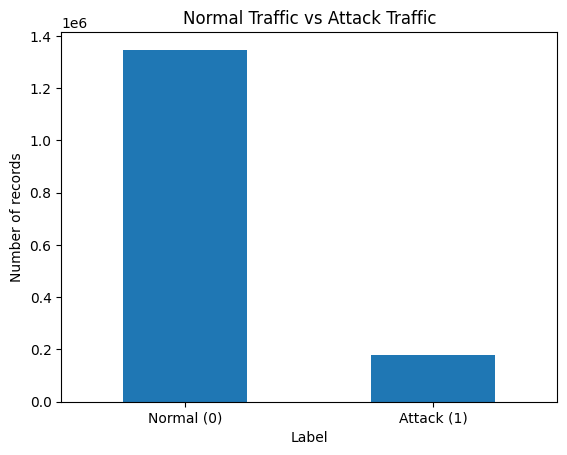

In [ ]:
train_df['Label'].value_counts().sort_index().plot(kind='bar', rot=0)
plt.xticks([0, 1], ['Normal (0)', 'Attack (1)'])
plt.ylabel('Number of records')
plt.title('Normal Traffic vs Attack Traffic')
plt.show()

In [ ]:
X_train = train_df[feature_names].copy()
y_train = train_df['Label'].astype(int)
X_val = val_df[feature_names].copy()
y_val = val_df['Label'].astype(int)
print('Training features:', X_train.shape)
print('Training labels:', y_train.shape)
print('Validation features:', X_val.shape)
print('Validation labels:', y_val.shape)

Training features: (1524028, 38)
Training labels: (1524028,)
Validation features: (381007, 38)
Validation labels: (381007,)


In [ ]:

# Identify categorical and numeric columns
categorical_features = ["proto", "state", "service"]

numeric_features = [
    col for col in feature_names
    if col not in categorical_features
]

# Clean empty strings and whitespace in the data
X_train_clean = X_train.replace(r"^\s*$", np.nan, regex=True)
X_val_clean = X_val.replace(r"^\s*$", np.nan, regex=True)

# Convert numeric columns to numbers
for col in numeric_features:
    X_train_clean[col] = pd.to_numeric(
        X_train_clean[col], errors="coerce"
    )
    X_val_clean[col] = pd.to_numeric(
        X_val_clean[col], errors="coerce"
    )

# Fill missing numeric values with the median
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Fill missing text values and encode categories
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant", fill_value="missing"
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline fixed!")

Preprocessing pipeline fixed!


In [ ]:

# Train the Random Forest model using cleaned data

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train_clean, y_train)

print("Model training completed!")

Model training completed!


In [ ]:

# Predict using the cleaned validation data
y_pred = model.predict(X_val_clean)

# Display the model's performance
print(classification_report(
    y_val,
    y_pred,
    target_names=["Normal", "Attack"],
    zero_division=0
))

              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00    336967
      Attack       0.99      0.97      0.98     44040

    accuracy                           1.00    381007
   macro avg       0.99      0.99      0.99    381007
weighted avg       1.00      1.00      1.00    381007



[[336323    644]
 [  1104  42936]]


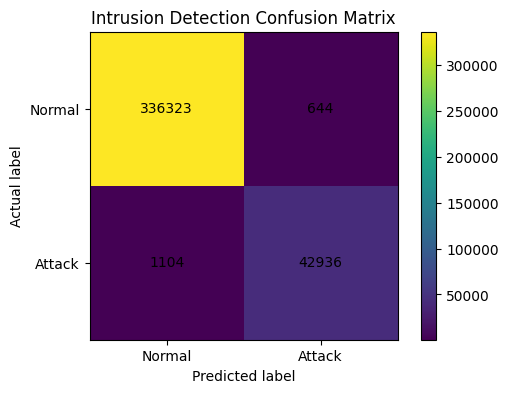

In [ ]:
cm = confusion_matrix(y_val, y_pred, labels=[0, 1])
print(cm)
plt.figure(figsize=(6, 4))
plt.imshow(cm)
plt.xticks([0, 1], ['Normal', 'Attack'])
plt.yticks([0, 1], ['Normal', 'Attack'])
plt.xlabel('Predicted label')
plt.ylabel('Actual label')
plt.title('Intrusion Detection Confusion Matrix')
for i in range(2):
    for j in range(2):
        plt.text(j, i, str(cm[i, j]), ha='center', va='center')
plt.colorbar()
plt.show()

In [ ]:

# Get attack probabilities from the cleaned validation data
y_prob = model.predict_proba(X_val_clean)[:, 1]

# Set the decision threshold
threshold = 0.30

# Convert probabilities into predictions
y_pred_tuned = (y_prob >= threshold).astype(int)

print("Threshold:", threshold)

print(classification_report(
    y_val,
    y_pred_tuned,
    target_names=["Normal", "Attack"],
    zero_division=0
))

Threshold: 0.3
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00    336967
      Attack       0.96      0.99      0.98     44040

    accuracy                           0.99    381007
   macro avg       0.98      0.99      0.99    381007
weighted avg       0.99      0.99      0.99    381007



In [ ]:

# COST SCORE AND MISSED ATTACK ANALYSIS

from sklearn.metrics import confusion_matrix, recall_score, precision_score

# Set example penalty weights
COST_MISSED_ATTACK = 10
COST_FALSE_ALARM = 1

# Get attack probabilities from the trained model
y_prob = model.predict_proba(X_val_clean)[:, 1]

# Evaluate different decision thresholds
thresholds = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70]

results = []

for threshold in thresholds:

    # Predict 1 = Attack, 0 = Normal
    predictions = (y_prob >= threshold).astype(int)

    # Get confusion matrix values
    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    # Calculate operational metrics
    missed_attacks = fn
    false_alarms = fp

    cost_score = (
        COST_MISSED_ATTACK * missed_attacks
        + COST_FALSE_ALARM * false_alarms
    )

    attack_recall = tp / (tp + fn) if (tp + fn) > 0 else 0

    results.append({
        "Threshold": threshold,
        "Detected Attacks": tp,
        "Missed Attacks": missed_attacks,
        "False Alarms": false_alarms,
        "Attack Recall": round(attack_recall, 4),
        "Cost Score": cost_score
    })

# Display all results
results_df = pd.DataFrame(results)

display(results_df)

# Find the threshold with the lowest cost score
best_result = results_df.loc[
    results_df["Cost Score"].idxmin()
]

print("\nBEST THRESHOLD BASED ON COST")
print(best_result)

print("\nExample cost weights:")
print("Missed attack penalty:", COST_MISSED_ATTACK)
print("False alarm penalty:", COST_FALSE_ALARM)

,Threshold,Detected Attacks,Missed Attacks,False Alarms,Attack Recall,Cost Score
0,0.1,44010,30,3033,0.9993,3333
1,0.2,43873,167,2398,0.9962,4068
2,0.3,43637,403,1664,0.9908,5694
3,0.4,43342,698,1072,0.9842,8052
4,0.5,42953,1087,659,0.9753,11529
5,0.6,42593,1447,392,0.9671,14862
6,0.7,42165,1875,213,0.9574,18963



BEST THRESHOLD BASED ON COST
Threshold               0.1000
Detected Attacks    44010.0000
Missed Attacks         30.0000
False Alarms         3033.0000
Attack Recall           0.9993
Cost Score           3333.0000
Name: 0, dtype: float64

Example cost weights:
Missed attack penalty: 10
False alarm penalty: 1


In [ ]:
print('Precision:', precision_score(y_val, y_pred_tuned, zero_division=0))
print('Attack Recall:', recall_score(y_val, y_pred_tuned, zero_division=0))
print('F1-score:', f1_score(y_val, y_pred_tuned, zero_division=0))
print('Average Precision:', average_precision_score(y_val, y_prob))

Precision: 0.963267919030485
Attack Recall: 0.9908492279745685
F1-score: 0.9768639258571092
Average Precision: 0.9986373849639305


TOP 10 INTRUSION DETECTION FEATURES:
num__smeansz    0.186233
num__sbytes     0.173502
num__Dload      0.062555
num__tcprtt     0.053456
num__Sload      0.053144
num__dur        0.052964
num__dmeansz    0.044609
num__ackdat     0.038606
num__dbytes     0.036572
num__Dpkts      0.033993
dtype: float64


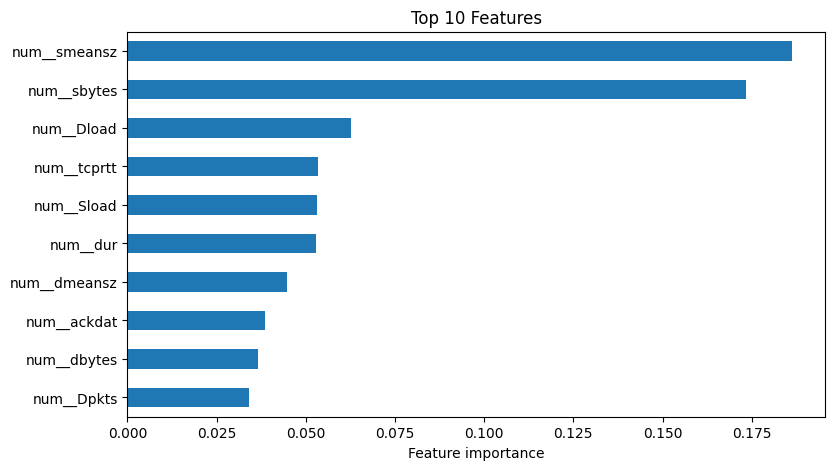

In [ ]:
fitted_preprocessor = model.named_steps['preprocessor']
classifier = model.named_steps['classifier']
feature_names_after_encoding = fitted_preprocessor.get_feature_names_out()
importances = pd.Series(classifier.feature_importances_, index=feature_names_after_encoding).sort_values(ascending=False)
print('TOP 10 INTRUSION DETECTION FEATURES:')
print(importances.head(10))
importances.head(10).sort_values().plot(kind='barh', figsize=(9, 5))
plt.xlabel('Feature importance')
plt.title('Top 10 Features')
plt.show()

In [ ]:

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

results = []

for name, classifier in models.items():
    print("Training:", name)

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", classifier)
    ])

    # Use cleaned training data
    pipeline.fit(X_train_clean, y_train)

    # Use cleaned validation data
    predictions = pipeline.predict(X_val_clean)

    results.append({
        "Model": name,
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, predictions, zero_division=0
        )
    })

results_df = pd.DataFrame(results)

display(results_df.sort_values("Recall", ascending=False))

Training: Logistic Regression


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Training: Random Forest
Training: Extra Trees


,Model,Precision,Recall,F1-score
2,Extra Trees,0.984827,0.975681,0.980233
1,Random Forest,0.985223,0.974932,0.980050
0,Logistic Regression,0.870890,0.908719,0.889403


In [ ]:
joblib.dump(model, 'model.joblib')
files.download('model.joblib')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from google.colab import files

uploaded_challenge = files.upload()

Saving challenge.csv to challenge.csv


In [ ]:

# Load challenge.csv (38 features, no labels)

challenge_df = pd.read_csv(
    "challenge.csv",
    header=None,
    names=feature_names
)

print("Challenge dataset shape:", challenge_df.shape)
display(challenge_df.head())

Challenge dataset shape: (254005, 38)


/tmp/ipykernel_2176/1923914361.py:3: DtypeWarning: Columns (30) have mixed types. Specify dtype option on import or set low_memory=False.
  challenge_df = pd.read_csv(


,proto,state,dur,sbytes,dbytes,sloss,dloss,service,Sload,Dload,...,ct_flw_http_mthd,is_ftp_login,ct_ftp_cmd,ct_srv_src,ct_srv_dst,ct_dst_ltm,ct_src_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm
0,udp,CON,0.1285,466,252,0,0,-,27441.063606,19040.79447,...,0.0,0.0,0,2,4,2,3,1,1,2
1,arp,INT,0.0000,85,0,0,0,-,0.000000,0.00000,...,0.0,0.0,0,2,2,2,2,2,2,2
2,arp,INT,0.0000,69,0,0,0,-,0.000000,0.00000,...,0.0,0.0,0,2,2,2,2,2,2,2
3,arp,INT,0.0000,39,0,0,0,-,0.000000,0.00000,...,0.0,0.0,0,2,2,2,2,2,2,2
4,arp,INT,0.0000,49,0,0,0,-,0.000000,0.00000,...,0.0,0.0,0,2,2,2,2,2,2,2


In [ ]:

# Clean blank strings and convert numeric columns

challenge_clean = challenge_df.replace(
    r"^\s*$", np.nan, regex=True
)

for col in numeric_features:
    challenge_clean[col] = pd.to_numeric(
        challenge_clean[col],
        errors="coerce"
    )

print("Challenge data cleaned!")
print("Rows:", len(challenge_clean))
print("Columns:", len(challenge_clean.columns))

Challenge data cleaned!
Rows: 254005
Columns: 38


In [ ]:

# Predict attack probabilities

challenge_prob = model.predict_proba(
    challenge_clean
)[:, 1]

# Use the threshold chosen in your cost-score analysis
best_threshold = float(best_result["Threshold"])

challenge_predictions = (
    challenge_prob >= best_threshold
).astype(int)

print("Threshold used:", best_threshold)
print("Total records:", len(challenge_predictions))
print("Predicted normal:", (challenge_predictions == 0).sum())
print("Predicted attacks:", (challenge_predictions == 1).sum())

Threshold used: 0.1
Total records: 254005
Predicted normal: 198298
Predicted attacks: 55707


In [ ]:

# Create a file containing challenge predictions

challenge_output = pd.DataFrame({
    "Label": challenge_predictions
})

challenge_output.to_csv(
    "challenge_predictions.csv",
    index=False
)

files.download("challenge_predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from sklearn.metrics import confusion_matrix
import pandas as pd

# Cost of each mistake
COST_MISSED_ATTACK = 10
COST_FALSE_ALARM = 1

# Get attack probabilities
y_prob = model.predict_proba(X_val_clean)[:, 1]

# Test different thresholds
thresholds = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70]

results = []

for threshold in thresholds:
    predictions = (y_prob >= threshold).astype(int)

    # Calculate confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    # Calculate cost
    cost_score = (
        COST_MISSED_ATTACK * fn
        + COST_FALSE_ALARM * fp
    )

    results.append({
        "Threshold": threshold,
        "Missed Attacks": fn,
        "False Alarms": fp,
        "Attack Recall": round(tp / (tp + fn), 4) if tp + fn else 0,
        "Cost Score": cost_score
    })

# Display comparison
results_df = pd.DataFrame(results)
display(results_df)

# Find the threshold with the lowest cost
best_result = results_df.loc[results_df["Cost Score"].idxmin()]

print("\nBEST RESULT")
print(best_result)

,Threshold,Missed Attacks,False Alarms,Attack Recall,Cost Score
0,0.1,30,3033,0.9993,3333
1,0.2,167,2398,0.9962,4068
2,0.3,403,1664,0.9908,5694
3,0.4,698,1072,0.9842,8052
4,0.5,1087,659,0.9753,11529
5,0.6,1447,392,0.9671,14862
6,0.7,1875,213,0.9574,18963



BEST RESULT
Threshold            0.1000
Missed Attacks      30.0000
False Alarms      3033.0000
Attack Recall        0.9993
Cost Score        3333.0000
Name: 0, dtype: float64
